# Sumativa 1 - Parte 2: Análisis bivariado e intervalos de confianza

**Dataset:** Framingham Heart Study (`data/framingham_limpio.csv`)  
**Variable de interés:** `TenYearCHD` (1 = desarrolla enfermedad coronaria en 10 años, 0 = no)

En esta parte se revisan las relaciones entre las variables y se comparan los participantes según el desarrollo de enfermedad coronaria. También se estiman medias y proporciones con intervalos de confianza al 95 %. Los resultados corresponden a asociaciones observadas y no permiten establecer causalidad.

Contenido:
1. Disponibilidad de los datos.
2. Correlaciones entre variables numéricas.
3. Comparaciones según `TenYearCHD`.
4. Estimaciones puntuales e intervalos de confianza.
5. Limitaciones y pasos siguientes.

## 0. Configuración y carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
np.random.seed(42)

FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

COLORES = {"principal": "#4C72B0", "riesgo": "#C44E52", "ic": "#55A868"}


def guardar_figura(nombre: str) -> None:
    # Ajusta, guarda en PNG a 200 dpi y muestra la figura actual.
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()


df = pd.read_csv("../data/framingham_limpio.csv")
NUM = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
NOMBRES = {
    "age": "Edad (años)", "cigsPerDay": "Cigarrillos por día",
    "totChol": "Colesterol total (mg/dL)", "sysBP": "Presión sistólica (mmHg)",
    "diaBP": "Presión diastólica (mmHg)", "BMI": "IMC (kg/m²)",
    "heartRate": "Frecuencia cardíaca (lpm)", "glucose": "Glucosa (mg/dL)",
}

print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]}")

Observaciones: 4240 | Variables: 16


## 1. Disponibilidad de datos

Se utiliza el archivo limpio generado en la Parte 1. Solo se imputaron los valores faltantes de `cigsPerDay`; las demás variables mantienen sus faltantes. En cada cálculo se usan los casos disponibles y se informa el tamaño de muestra correspondiente.

In [2]:
disponibilidad = pd.DataFrame({
    "n_observado": df[NUM].count(),
    "n_faltante": df[NUM].isna().sum(),
    "%_faltante": df[NUM].isna().mean().mul(100),
})
disponibilidad.index = [NOMBRES[c] for c in disponibilidad.index]
disponibilidad.round(2)

,n_observado,n_faltante,%_faltante
Edad (años),4240,0,0.000
Cigarrillos por día,4240,0,0.000
Colesterol total (mg/dL),4190,50,1.180
Presión sistólica (mmHg),4240,0,0.000
Presión diastólica (mmHg),4240,0,0.000
IMC (kg/m²),4221,19,0.450
Frecuencia cardíaca (lpm),4239,1,0.020
Glucosa (mg/dL),3852,388,9.150


`glucose` tiene el menor tamaño muestral (n = 3.852), mientras que edad, cigarrillos, presión sistólica y diastólica están disponibles para las 4.240 observaciones. Esta diferencia debe considerarse al comparar precisión entre estimaciones.

## 2. Relación entre variables numéricas

Se usa la correlación de Spearman porque varias variables son asimétricas, contienen valores extremos o concentran muchos ceros. El coeficiente se calcula a partir de rangos y permite detectar relaciones monótonas sin exigir normalidad. Cada par se calcula con las observaciones disponibles en ambas variables.

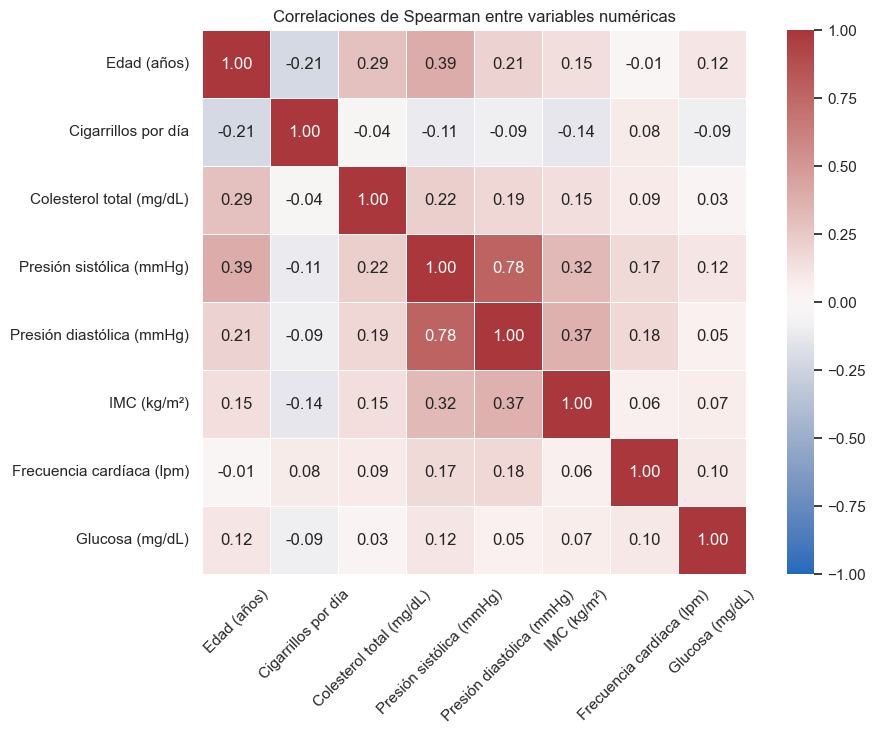

In [3]:
corr = df[NUM].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax,
            xticklabels=[NOMBRES[c] for c in NUM],
            yticklabels=[NOMBRES[c] for c in NUM])
ax.set_title("Correlaciones de Spearman entre variables numéricas")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
guardar_figura("p2_fig1_correlaciones")

In [4]:
pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
              .stack().rename("rho").reset_index())
pares["abs_rho"] = pares["rho"].abs()
pares = pares.sort_values("abs_rho", ascending=False).drop(columns="abs_rho")
pares.head(10)

,level_0,level_1,rho
18,sysBP,diaBP,0.778
2,age,sysBP,0.391
22,diaBP,BMI,0.375
19,sysBP,BMI,0.324
1,age,totChol,0.289
13,totChol,sysBP,0.224
0,age,cigsPerDay,-0.213
3,age,diaBP,0.208
14,totChol,diaBP,0.185
23,diaBP,heartRate,0.179


La correlación más alta corresponde a la presión sistólica y diastólica (ρ = 0,78), lo que resulta esperable porque ambas miden componentes de la presión arterial. También se observa una relación moderada entre edad y presión sistólica (ρ = 0,39), y entre IMC y presión diastólica (ρ = 0,38). El resto de los coeficientes es bajo. Estas relaciones pueden estar afectadas por otras variables y no indican causalidad.

## 3. Variables numéricas y enfermedad coronaria

Para cada variable se comparan las medias de quienes desarrollaron CHD y quienes no. Se informa la diferencia `CHD − sin CHD`, su intervalo de confianza del 95 % calculado con el método de Welch y el tamaño del efecto *g* de Hedges. Las dos pruebas de hipótesis exigidas en la evaluación se desarrollan en la Parte 3.

In [5]:
def comparacion_chd(variable: str) -> pd.Series:
    # Resumen bivariado, IC de Welch y g de Hedges para CHD frente a no CHD.
    con_chd = df.loc[df["TenYearCHD"] == 1, variable].dropna()
    sin_chd = df.loc[df["TenYearCHD"] == 0, variable].dropna()
    prueba = stats.ttest_ind(con_chd, sin_chd, equal_var=False)
    ic = prueba.confidence_interval(confidence_level=0.95)
    n1, n0 = len(con_chd), len(sin_chd)
    sd_comb = np.sqrt(((n1 - 1) * con_chd.var() + (n0 - 1) * sin_chd.var()) / (n1 + n0 - 2))
    d = (con_chd.mean() - sin_chd.mean()) / sd_comb
    correccion = 1 - 3 / (4 * (n1 + n0) - 9)
    return pd.Series({
        "n_sin_CHD": n0, "n_con_CHD": n1,
        "media_sin_CHD": sin_chd.mean(), "media_con_CHD": con_chd.mean(),
        "diferencia": con_chd.mean() - sin_chd.mean(),
        "IC95_inf": ic.low, "IC95_sup": ic.high,
        "g_Hedges": correccion * d,
    })


tabla_bivariada = pd.DataFrame({c: comparacion_chd(c) for c in NUM}).T
tabla_bivariada.index = [NOMBRES[c] for c in tabla_bivariada.index]
tabla_bivariada[["n_sin_CHD", "n_con_CHD"]] = tabla_bivariada[["n_sin_CHD", "n_con_CHD"]].astype(int)
tabla_bivariada.round(2)

,n_sin_CHD,n_con_CHD,media_sin_CHD,media_con_CHD,diferencia,IC95_inf,IC95_sup,g_Hedges
Edad (años),3596,644,48.760,54.150,5.380,4.710,6.060,0.640
Cigarrillos por día,3596,644,8.800,10.660,1.860,0.780,2.940,0.160
Colesterol total (mg/dL),3555,635,235.150,245.390,10.240,6.230,14.250,0.230
Presión sistólica (mmHg),3596,644,130.340,143.620,13.280,11.110,15.450,0.620
Presión diastólica (mmHg),3596,644,82.170,86.980,4.810,3.670,5.960,0.410
IMC (kg/m²),3587,634,25.670,26.530,0.860,0.480,1.240,0.210
Frecuencia cardíaca (lpm),3596,643,75.760,76.530,0.770,-0.260,1.790,0.060
Glucosa (mg/dL),3258,594,80.680,89.010,8.330,4.950,11.710,0.350


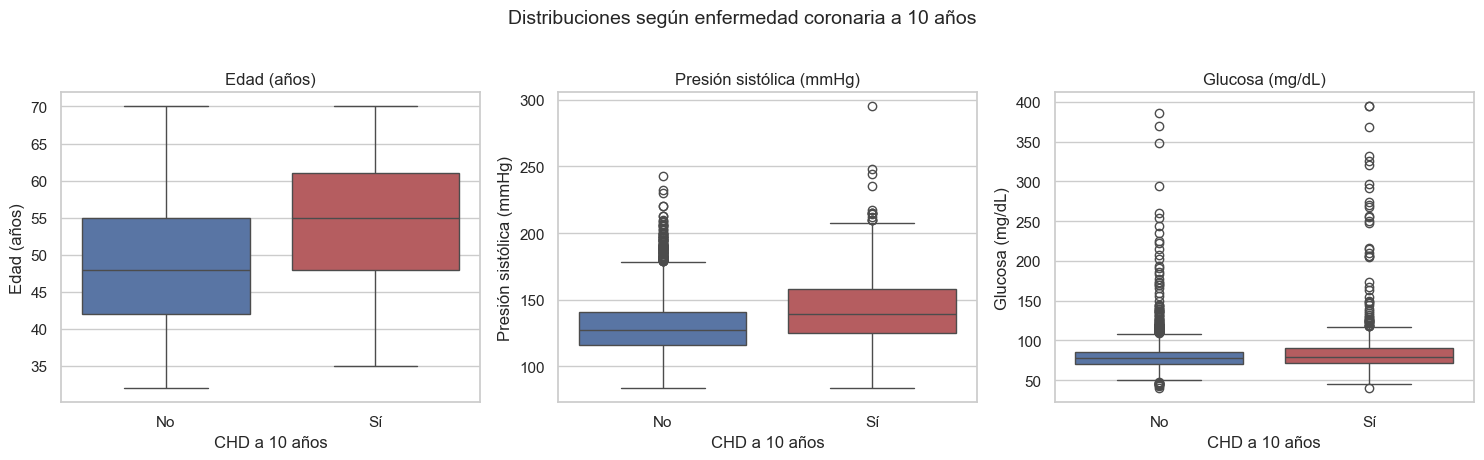

In [6]:
seleccion = ["age", "sysBP", "glucose"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, variable in zip(axes, seleccion):
    sns.boxplot(data=df, x="TenYearCHD", y=variable, hue="TenYearCHD",
                legend=False, palette=[COLORES["principal"], COLORES["riesgo"]], ax=ax)
    ax.set_xticks([0, 1], ["No", "Sí"])
    ax.set(xlabel="CHD a 10 años", ylabel=NOMBRES[variable], title=NOMBRES[variable])
plt.suptitle("Distribuciones según enfermedad coronaria a 10 años", fontsize=14, y=1.02)
guardar_figura("p2_fig2_numericas_chd")

Las mayores diferencias estandarizadas se observan en edad (*g* ≈ 0,64) y presión sistólica (*g* ≈ 0,62): el grupo con CHD tiene en promedio 5,4 años más y 13,3 mmHg adicionales. La glucosa también es mayor en el grupo con CHD, pero su distribución es muy asimétrica y contiene menos casos observados. La frecuencia cardíaca muestra una diferencia pequeña cuyo IC incluye cero. Ninguna comparación está ajustada por edad, sexo u otros factores.

## 4. Variables categóricas y enfermedad coronaria

Se calculan las tasas de CHD para algunos grupos de interés. Los intervalos se obtienen con el método de Wilson, que es más estable que la aproximación normal cuando hay pocos casos.

In [7]:
CATEGORICAS = {
    "male": {0: "Mujer", 1: "Hombre"},
    "currentSmoker": {0: "No fumador", 1: "Fumador"},
    "prevalentHyp": {0: "Sin hipertensión", 1: "Con hipertensión"},
    "diabetes": {0: "Sin diabetes", 1: "Con diabetes"},
    "prevalentStroke": {0: "Sin ACV previo", 1: "Con ACV previo"},
}


def tasa_chd(variable: str, valor: int, etiqueta: str) -> dict:
    grupo = df.loc[df[variable] == valor, "TenYearCHD"].dropna()
    eventos, n = int(grupo.sum()), int(grupo.count())
    inferior, superior = proportion_confint(eventos, n, alpha=0.05, method="wilson")
    return {
        "variable": variable, "grupo": etiqueta, "n": n, "eventos": eventos,
        "tasa_%": eventos / n * 100, "IC95_inf_%": inferior * 100, "IC95_sup_%": superior * 100,
    }


filas = []
for variable, etiquetas in CATEGORICAS.items():
    for valor, etiqueta in etiquetas.items():
        filas.append(tasa_chd(variable, valor, etiqueta))

tabla_tasas = pd.DataFrame(filas)
tabla_tasas.round(2)

,variable,grupo,n,eventos,tasa_%,IC95_inf_%,IC95_sup_%
0,male,Mujer,2420,301,12.440,11.180,13.810
1,male,Hombre,1820,343,18.850,17.120,20.710
2,currentSmoker,No fumador,2145,311,14.500,13.070,16.050
3,currentSmoker,Fumador,2095,333,15.890,14.390,17.520
4,prevalentHyp,Sin hipertensión,2923,319,10.910,9.830,12.100
5,prevalentHyp,Con hipertensión,1317,325,24.680,22.420,27.080
6,diabetes,Sin diabetes,4131,604,14.620,13.580,15.730
7,diabetes,Con diabetes,109,40,36.700,28.250,46.050
8,prevalentStroke,Sin ACV previo,4215,633,15.020,13.970,16.130
9,prevalentStroke,Con ACV previo,25,11,44.000,26.670,62.930


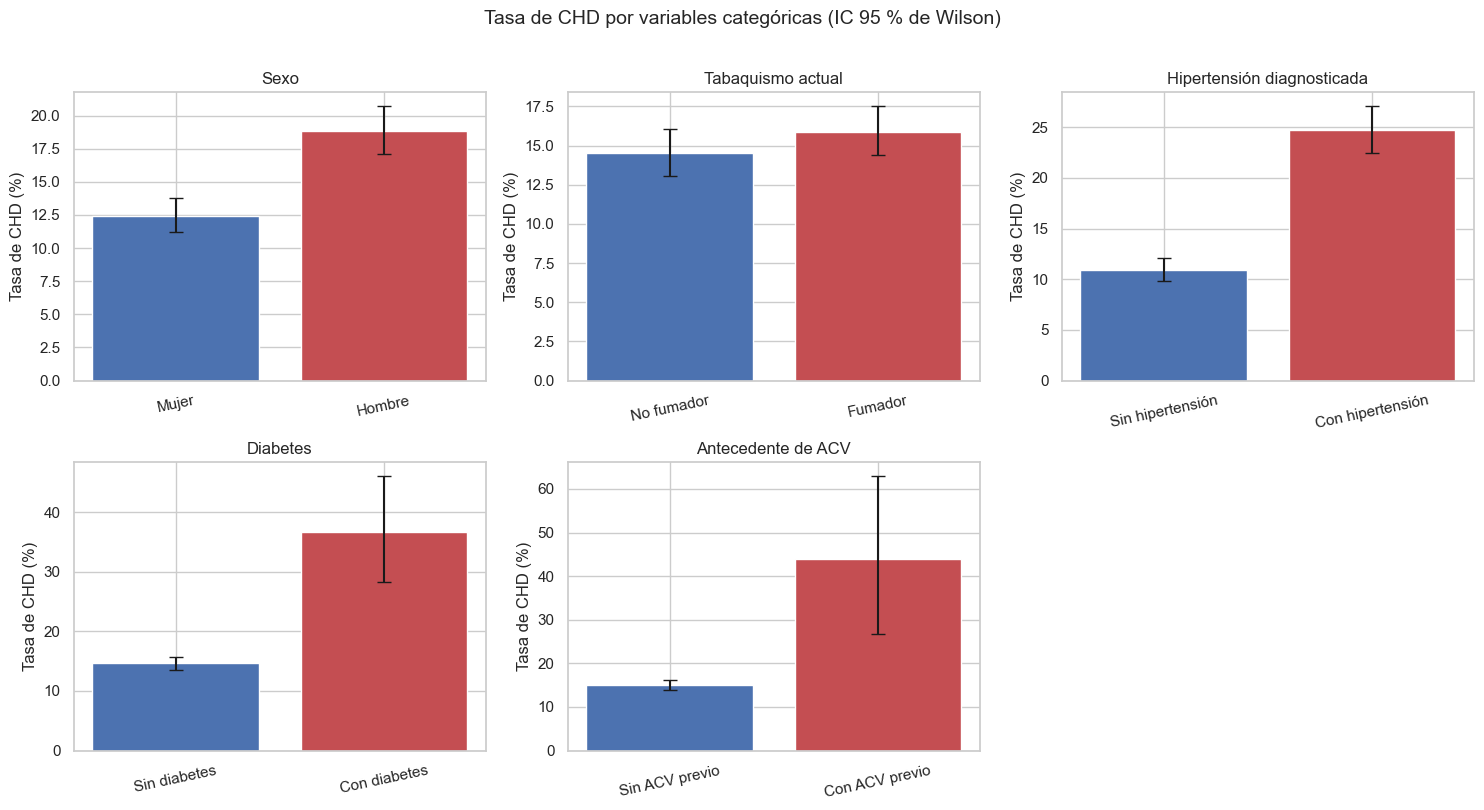

In [8]:
TITULOS_CAT = {
    "male": "Sexo",
    "currentSmoker": "Tabaquismo actual",
    "prevalentHyp": "Hipertensión diagnosticada",
    "diabetes": "Diabetes",
    "prevalentStroke": "Antecedente de ACV",
}

orden_variables = list(CATEGORICAS)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, variable in zip(axes.ravel(), orden_variables):
    t = tabla_tasas.query("variable == @variable")
    yerr = np.vstack([t["tasa_%"] - t["IC95_inf_%"], t["IC95_sup_%"] - t["tasa_%"]])
    ax.bar(t["grupo"], t["tasa_%"], yerr=yerr, capsize=5,
           color=[COLORES["principal"], COLORES["riesgo"]])
    ax.set(ylabel="Tasa de CHD (%)", title=TITULOS_CAT[variable])
    ax.tick_params(axis="x", rotation=12)
axes.ravel()[-1].axis("off")
plt.suptitle("Tasa de CHD por variables categóricas (IC 95 % de Wilson)", fontsize=14, y=1.01)
guardar_figura("p2_fig3_tasas_chd")

La tasa de CHD es mayor entre hombres (18,8 % frente a 12,4 %), personas con hipertensión (24,7 % frente a 10,9 %) y personas con diabetes (36,7 % frente a 14,6 %). El grupo con ACV previo tiene solo 25 observaciones, por lo que su intervalo es amplio y la estimación es inestable. La diferencia cruda por tabaquismo es pequeña; la Parte 3 muestra que la edad actúa como posible confusor.

## 5. Estimaciones puntuales e intervalos de confianza

Se seleccionan edad, presión sistólica y colesterol total porque son variables numéricas directamente relacionadas con el problema cardiovascular. En los tres casos se estima la media.

El intervalo de confianza se calcula como media ± *t* crítico × error estándar. El método supone observaciones independientes. Aunque presión y colesterol no siguen una distribución normal, sus muestras superan las 4.000 observaciones, por lo que la distribución de la media puede aproximarse mediante el Teorema Central del Límite. Estos intervalos representan la variabilidad muestral, pero no corrigen posibles sesgos de selección ni problemas producidos por los datos faltantes.

In [9]:
def ic_media_t(s: pd.Series, confianza: float = 0.95) -> pd.Series:
    # Estimación de la media e IC t bilateral usando casos observados.
    s = s.dropna()
    media = s.mean()
    error = stats.sem(s)
    inferior, superior = stats.t.interval(confianza, df=len(s) - 1, loc=media, scale=error)
    return pd.Series({
        "n": len(s), "estimacion_media": media, "error_estandar": error,
        "IC95_inf": inferior, "IC95_sup": superior,
    })


VARIABLES_IC = ["age", "sysBP", "totChol"]
tabla_ic = pd.DataFrame({c: ic_media_t(df[c]) for c in VARIABLES_IC}).T
tabla_ic.index = [NOMBRES[c] for c in tabla_ic.index]
tabla_ic["n"] = tabla_ic["n"].astype(int)
tabla_ic.round(2)

,n,estimacion_media,error_estandar,IC95_inf,IC95_sup
Edad (años),4240,49.580,0.130,49.320,49.840
Presión sistólica (mmHg),4240,132.350,0.340,131.690,133.020
Colesterol total (mg/dL),4190,236.700,0.690,235.350,238.050


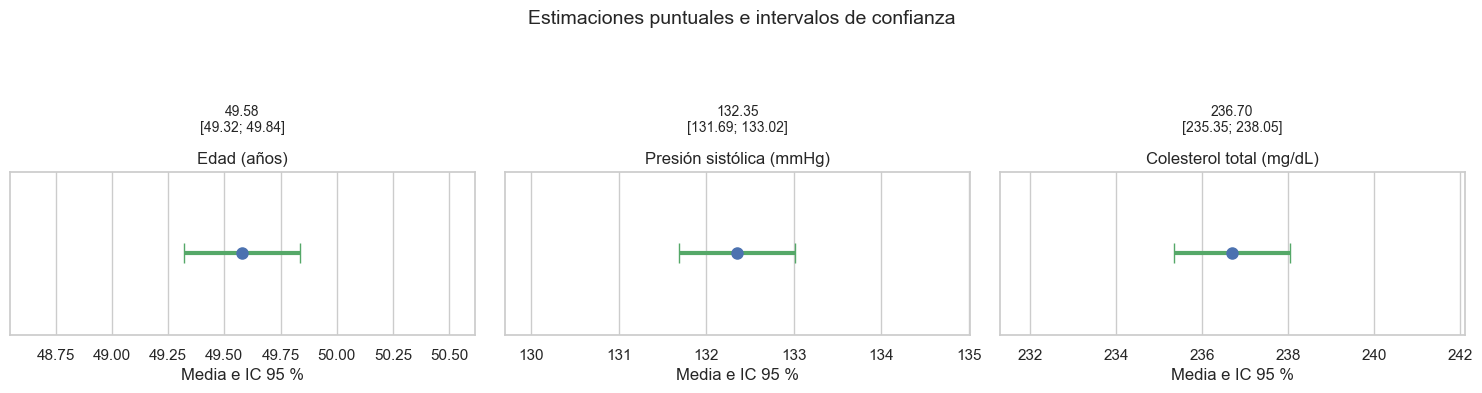

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (etiqueta, fila) in zip(axes, tabla_ic.iterrows()):
    estimacion = fila["estimacion_media"]
    inferior = fila["IC95_inf"]
    superior = fila["IC95_sup"]
    margen = max((superior - inferior) * 1.5, abs(estimacion) * 0.005)
    ax.errorbar(estimacion, 0, xerr=[[estimacion - inferior], [superior - estimacion]],
                fmt="o", markersize=8, color=COLORES["principal"],
                ecolor=COLORES["ic"], elinewidth=3, capsize=7)
    ax.set_xlim(inferior - margen, superior + margen)
    ax.set_yticks([])
    ax.set(title=etiqueta, xlabel="Media e IC 95 %")
    ax.text(estimacion, 0.08, f"{estimacion:.2f}\n[{inferior:.2f}; {superior:.2f}]",
            ha="center", va="bottom", fontsize=10)
plt.suptitle("Estimaciones puntuales e intervalos de confianza", fontsize=14, y=1.03)
guardar_figura("p2_fig4_ic_medias")

Interpretación de los intervalos:
- **Edad:** media de 49,58 años; IC 95 % [49,32; 49,84].
- **Presión sistólica:** media de 132,35 mmHg; IC 95 % [131,69; 133,02].
- **Colesterol total:** media de 236,70 mg/dL; IC 95 % [235,35; 238,05], usando 4.190 observaciones.

La interpretación frecuentista es que, al repetir el procedimiento muchas veces, aproximadamente el 95 % de los intervalos contendría la media poblacional. El tamaño de muestra explica que los intervalos sean estrechos, aunque esto no garantiza que la cohorte represente a otras poblaciones.

### 5.1 Estimación complementaria de la proporción de CHD

In [11]:
eventos = int(df["TenYearCHD"].sum())
n = int(df["TenYearCHD"].count())
ic_prop = proportion_confint(eventos, n, alpha=0.05, method="wilson")
pd.DataFrame({
    "n": [n], "eventos": [eventos], "proporcion_estimada_%": [eventos / n * 100],
    "IC95_inf_%": [ic_prop[0] * 100], "IC95_sup_%": [ic_prop[1] * 100],
}, index=["CHD a 10 años"]).round(2)

,n,eventos,proporcion_estimada_%,IC95_inf_%,IC95_sup_%
CHD a 10 años,4240,644,15.190,14.140,16.300


La proporción observada de CHD a 10 años es 15,19 %, con IC de Wilson al 95 % [14,14 %; 16,30 %]. Esta estimación complementa las medias y ayuda a dimensionar el desbalance de la variable objetivo.

## 6. Limitaciones

- Los participantes pertenecen a una cohorte histórica de Framingham, por lo que los resultados no representan necesariamente a la población chilena ni a la población actual.
- Se trabaja con los casos disponibles. Si los faltantes están relacionados con variables clínicas, puede existir sesgo.
- Las comparaciones son crudas y no controlan simultáneamente edad, sexo, hipertensión, diabetes y tabaquismo.
- Los grupos con antecedente de ACV y diabetes tienen pocos casos y, por lo tanto, intervalos más amplios.
- Se revisan varias asociaciones con fines exploratorios. Los resultados sirven para orientar análisis posteriores, no para confirmar múltiples efectos independientes.

## 7. Síntesis y próximos pasos

- Edad y presión sistólica presentan las diferencias más marcadas entre los grupos con y sin CHD.
- Las tasas de CHD son mayores entre hombres y entre quienes tienen hipertensión o diabetes, aunque estas comparaciones aún no están ajustadas.
- Se estimaron las medias de edad, presión sistólica y colesterol total con intervalos de confianza del 95 %.
- En la Parte 3 se realizan las pruebas de hipótesis. Más adelante será necesario ajustar un modelo de regresión logística, estudiar interacciones, tratar los faltantes y validar el modelo fuera de la muestra de entrenamiento.